# Schema và chất lượng dữ liệu

Phụ trách: **Dương Phan Minh Trí — 24120470** (Nhánh `feat/data-storage`).

Chương này tập trung kiểm chứng cấu trúc lưu trữ dữ liệu (PyArrow Schema), đánh giá chất lượng dữ liệu thu thập (tỷ lệ khuyết thiếu, tính toàn vẹn khóa chính và liên kết tham chiếu khóa ngoại), cũng như thống kê kết quả hợp nhất từ các phân vùng của 5 thành viên trong nhóm.

## Mục lục

1. Schema hai bảng Parquet & Chuẩn xuất dữ liệu đề bài
2. Tỷ lệ khuyết thiếu (Missing Rate) và Tính toàn vẹn tham chiếu
3. Phân bố phiên bản (Versions) & Tình trạng tải nguồn
4. Thống kê đóng góp phân vùng & Xuất số liệu tổng hợp


In [1]:
import json
import os
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, HTML

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial"]

CANDIDATE_DIRS = [
    Path("../data/processed"),
    Path("data/processed"),
    Path("../data/mock/processed"),
    Path("data/mock/processed"),
]

PROCESSED_DIR = None
for d in CANDIDATE_DIRS:
    if (d / "publications.parquet").exists() and (d / "references.parquet").exists() and (d / "overall_stats.json").exists():
        PROCESSED_DIR = d
        break

if PROCESSED_DIR is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục dữ liệu hợp lệ (cần đủ publications.parquet, references.parquet, overall_stats.json). "
        f"Đã thử 4 đường dẫn: {[str(d) for d in CANDIDATE_DIRS]}"
    )

print(f"Đang sử dụng thư mục dữ liệu: {PROCESSED_DIR}")

METRICS_DIR = Path("../docs/metrics")
if not METRICS_DIR.parent.exists():
    METRICS_DIR = Path("docs/metrics")

EXPORT_METRICS = False  # Mặc định False; chỉ xuất metrics khi chạy thực nghiệm chính thức

pub_path = PROCESSED_DIR / "publications.parquet"
ref_path = PROCESSED_DIR / "references.parquet"
stats_path = PROCESSED_DIR / "overall_stats.json"

with open(stats_path, encoding="utf-8") as f:
    overall_stats = json.load(f)

is_mock = overall_stats.get("is_mock", False)

if is_mock:
    display(HTML("""
    <div style="background-color: #fff3cd; color: #856404; padding: 15px; border-radius: 5px; border: 1px solid #ffeeba; margin-bottom: 20px;">
        <h4 style="margin-top: 0;">⚠️ CẢNH BÁO: ĐANG SỬ DỤNG DỮ LIỆU GIẢ LẬP (MOCK DATA)</h4>
        <p style="margin-bottom: 0;">Các số liệu và biểu đồ phân tích dưới đây được tạo từ bộ dữ liệu mẫu (seed 42) phục vụ kiểm chứng chức năng pipeline. Số liệu này <strong>không được dùng làm kết luận thực nghiệm</strong> trong báo cáo cuối cùng.</p>
    </div>
    """))
else:
    display(Markdown("> ✅ **Trạng thái:** Dữ liệu đang được phân tích là **DỮ LIỆU CÀO THẬT (REAL DATA)** từ arXiv và Semantic Scholar."))

pub_table = pq.read_table(pub_path)
ref_table = pq.read_table(ref_path)

df_pubs = pub_table.to_pandas()
df_refs = ref_table.to_pandas()

print(f"Đã tải {len(df_pubs):,} bài báo và {len(df_refs):,} trích dẫn từ {PROCESSED_DIR}")


Đang sử dụng thư mục dữ liệu: ../data/mock/processed


Đã tải 24 bài báo và 20 trích dẫn từ ../data/mock/processed


## 1. Schema hai bảng Parquet & Chuẩn xuất dữ liệu đề bài

Hệ thống lưu trữ áp dụng **Working Schema mở rộng** (16 cột cho publications và 11 cột cho references) nhằm lưu giữ đầy đủ nhất metadata bài viết, dung lượng và trạng thái của từng phiên bản, đồng thời có thể trích xuất chính xác 6 cột theo yêu cầu đề bài Lab Book.

In [2]:
schema_summary = []
for field in pub_table.schema:
    schema_summary.append({"Table": "publications", "Field": field.name, "Type": str(field.type), "Nullable": field.nullable})
for field in ref_table.schema:
    schema_summary.append({"Table": "references", "Field": field.name, "Type": str(field.type), "Nullable": field.nullable})

df_schemas = pd.DataFrame(schema_summary)
print("=== BẢNG TỔNG KẾT SCHEMA PYARROW ===")
display(df_schemas.head(16))
display(df_schemas.tail(11))

=== BẢNG TỔNG KẾT SCHEMA PYARROW ===


,Table,Field,Type,Nullable
0,publications,id,string,False
1,publications,title,string,True
2,publications,abstract,string,True
3,publications,authors,list<element: string>,True
4,publications,primary_category,string,True
5,publications,categories,list<element: string>,True
6,publications,published,"timestamp[us, tz=UTC]",True
7,publications,updated,"timestamp[us, tz=UTC]",True
8,publications,doi,string,True
9,publications,journal_ref,string,True


,Table,Field,Type,Nullable
16,references,arxiv_id,string,False
17,references,ref_arxiv_id,string,True
18,references,ref_title,string,True
19,references,ref_authors,list<element: string>,True
20,references,ref_submission_date,string,True
21,references,ref_s2_id,string,True
22,references,ref_doi,string,True
23,references,ref_year,int32,True
24,references,ref_venue,string,True
25,references,raw_citation,string,True


## 2. Tỷ lệ khuyết thiếu (Missing Rate) và Tính toàn vẹn tham chiếu

Đánh giá tỷ lệ khuyết thiếu các trường để hiểu độ hoàn chỉnh của dữ liệu thu được từ arXiv API và Semantic Scholar.

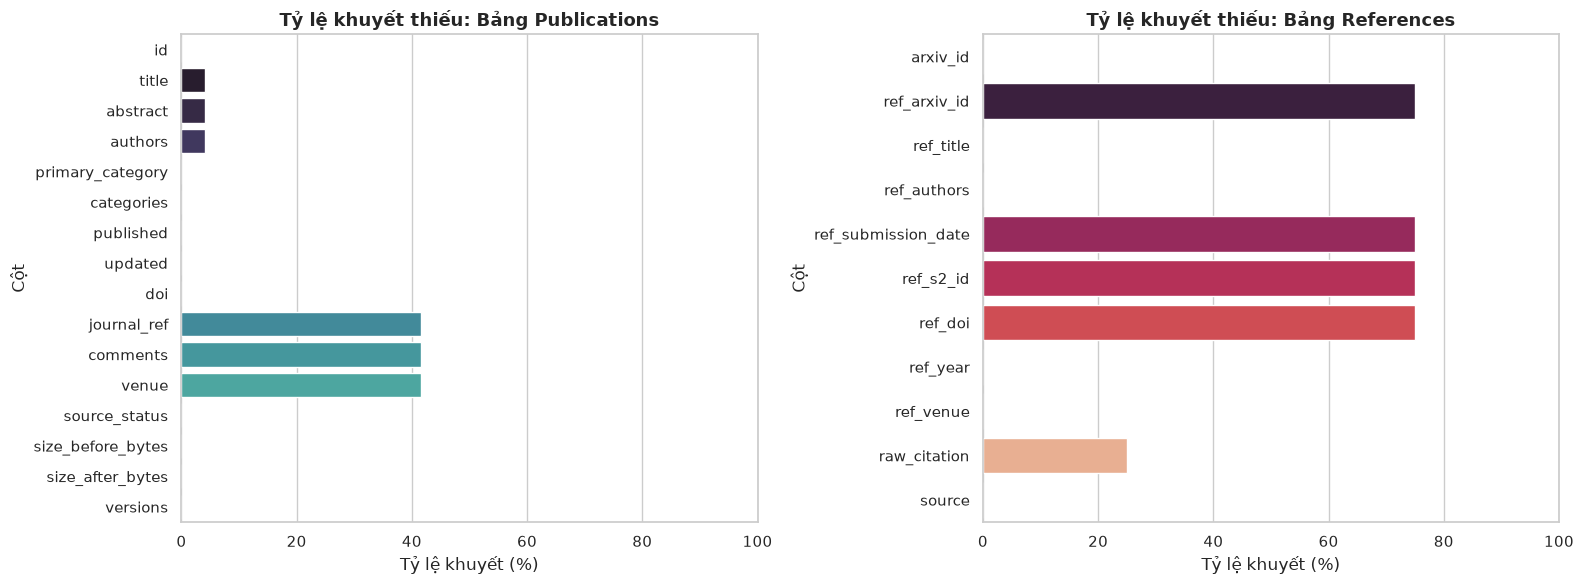

=== KIỂM TRA KHÓA & TOÀN VẸN DỮ LIỆU ===
* Tổng bài báo duy nhất (Unique IDs): 24
* Số lượng bài trùng khóa chính: 0
* Số trích dẫn mồ côi (Orphan references): 0


In [3]:
def compute_missing_rates(df: pd.DataFrame, table_name: str) -> pd.DataFrame:
    missing_counts = df.isna().sum()
    # Xử lý trường list/array rỗng đối với authors/categories/versions
    for col in df.columns:
        if df[col].apply(lambda x: isinstance(x, (list, tuple, np.ndarray))).any():
            missing_counts[col] = df[col].apply(lambda x: len(x) == 0 if isinstance(x, (list, tuple, np.ndarray)) else pd.isna(x)).sum()
    missing_rates = (missing_counts / len(df) * 100).round(2)
    res = pd.DataFrame({
        "Cột": df.columns,
        "Số dòng khuyết": missing_counts,
        "Tỷ lệ khuyết (%)": missing_rates,
    }).reset_index(drop=True)
    res["Bảng"] = table_name
    return res

missing_pubs = compute_missing_rates(df_pubs, "publications")
missing_refs = compute_missing_rates(df_refs, "references")
df_all_missing = pd.concat([missing_pubs, missing_refs], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=missing_pubs, x="Tỷ lệ khuyết (%)", y="Cột", ax=axes[0], hue="Cột", palette="mako", legend=False)
axes[0].set_title("Tỷ lệ khuyết thiếu: Bảng Publications", fontsize=13, fontweight="bold")
axes[0].set_xlim(0, 100)

sns.barplot(data=missing_refs, x="Tỷ lệ khuyết (%)", y="Cột", ax=axes[1], hue="Cột", palette="rocket", legend=False)
axes[1].set_title("Tỷ lệ khuyết thiếu: Bảng References", fontsize=13, fontweight="bold")
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()

# Kiểm tra tính toàn vẹn khóa tham chiếu (Referential Integrity)
pub_id_set = set(df_pubs["id"].dropna())
ref_source_set = set(df_refs["arxiv_id"].dropna())
orphan_refs = df_refs[~df_refs["arxiv_id"].isin(pub_id_set)]

print("=== KIỂM TRA KHÓA & TOÀN VẸN DỮ LIỆU ===")
print(f"* Tổng bài báo duy nhất (Unique IDs): {len(pub_id_set):,}")
print(f"* Số lượng bài trùng khóa chính: {len(df_pubs) - len(pub_id_set)}")
print(f"* Số trích dẫn mồ côi (Orphan references): {len(orphan_refs):,}")


## 3. Phân bố phiên bản (Versions) & Tình trạng tải nguồn

Thống kê số lượng phiên bản của các bài báo khoa học và phân tích trạng thái tải mã nguồn LaTeX toàn văn.

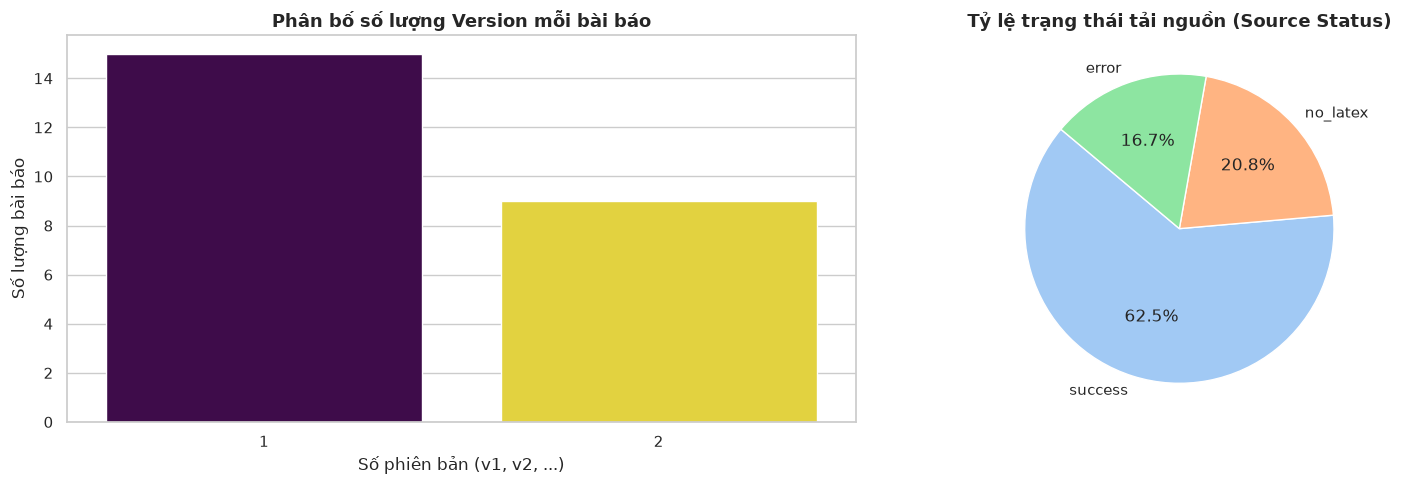

* Số version trung bình mỗi bài: 1.38
* Tỷ lệ bài có từ 2 version trở lên: 37.5%


In [4]:
df_pubs["num_versions"] = df_pubs["versions"].apply(lambda v: len(v) if isinstance(v, (list, tuple, np.ndarray)) else 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Biểu đồ phân bố số version
version_counts = df_pubs["num_versions"].value_counts().sort_index()
sns.barplot(x=version_counts.index, y=version_counts.values, ax=axes[0], hue=version_counts.index, palette="viridis", legend=False)
axes[0].set_title("Phân bố số lượng Version mỗi bài báo", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Số phiên bản (v1, v2, ...)")
axes[0].set_ylabel("Số lượng bài báo")

# 2. Biểu đồ trạng thái tải nguồn (Source Status)
status_counts = df_pubs["source_status"].fillna("unknown").value_counts()
axes[1].pie(status_counts.values, labels=status_counts.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("pastel"))
axes[1].set_title("Tỷ lệ trạng thái tải nguồn (Source Status)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

print(f"* Số version trung bình mỗi bài: {df_pubs['num_versions'].mean():.2f}")
print(f"* Tỷ lệ bài có từ 2 version trở lên: {(df_pubs['num_versions'] > 1).mean() * 100:.1f}%")


## 4. Thống kê đóng góp phân vùng & Xuất số liệu tổng hợp

Tổng hợp tiến độ và số lượng bản ghi của 5 thành viên trong nhóm, đồng thời xuất các bảng số liệu rút gọn phục vụ việc biên dịch Jupyter Book trên repository độc lập (`arxiv-harvester-book`).

In [5]:
def _safe_float(val):
    return float(val) if val is not None else None

members_df = pd.DataFrame(overall_stats.get("member_breakdown", []))
if not members_df.empty:
    display(members_df[["member_id", "publications_count", "references_count", "runtime_sec", "peak_rss_mb", "avg_rss_mb"]])

# Chỉ xuất file ra docs/metrics/ khi là dữ liệu thật (không phải mock) VÀ EXPORT_METRICS=True
if not is_mock and EXPORT_METRICS:
    METRICS_DIR.mkdir(parents=True, exist_ok=True)
    metrics_summary = {
        "total_publications": int(len(df_pubs)),
        "total_references": int(len(df_refs)),
        "orphan_references": int(len(orphan_refs)),
        "avg_versions_per_paper": _safe_float(round(df_pubs["num_versions"].mean(), 2)),
        "paper_crawl_success_rate": _safe_float(overall_stats.get("paper_crawl_success_rate")),
        "paper_success_rate_from_stats": _safe_float(overall_stats.get("paper_success_rate_from_stats")),
        "source_version_coverage_rate": _safe_float(overall_stats.get("source_version_coverage_rate")),
        "peak_rss_mb": _safe_float(overall_stats.get("resource_performance", {}).get("peak_rss_mb")),
        "weighted_avg_rss_mb": _safe_float(overall_stats.get("resource_performance", {}).get("weighted_avg_rss_mb")),
    }
    with open(METRICS_DIR / "quality_summary.json", "w", encoding="utf-8") as f:
        json.dump(metrics_summary, f, ensure_ascii=False, indent=2)
    df_all_missing.to_csv(METRICS_DIR / "missing_rates.csv", index=False)
    print(f"✅ Đã xuất thành công số liệu tổng kết vào {METRICS_DIR}/")
elif is_mock:
    print("ℹ️ Dữ liệu Mock: Bỏ qua bước xuất file ra docs/metrics/ theo đúng nguyên tắc liêm chính học thuật.")
else:
    print("ℹ️ EXPORT_METRICS=False: Bỏ qua xuất file ra docs/metrics/. Đổi EXPORT_METRICS=True nếu muốn lưu số liệu.")


,member_id,publications_count,references_count,runtime_sec,peak_rss_mb,avg_rss_mb
0,24120237,5,4,19.464,164.19,100.30
1,24120282,5,4,27.789,121.50,88.25
2,24120438,5,4,32.844,125.22,92.66
3,24120470,5,4,15.596,133.12,95.16
4,24120474,5,4,15.531,131.93,99.50


ℹ️ Dữ liệu Mock: Bỏ qua bước xuất file ra docs/metrics/ theo đúng nguyên tắc liêm chính học thuật.
